# Model pipeline

Loads a trained run (DTNet or the feedforward baseline) from its checkpoint and saved config,
then shows its training curves, sample mazes, how well it generalizes to **unseen
generators**, **larger mazes** and **mazes with loops** (10% of walls removed), and an error
analysis of why it fails.

- **DTNet** (recurrent ResNet with recall and progressive loss, Bansal et al. 2022) can run
  more recurrent iterations at test time, so larger mazes can get more computation.
- **Feedforward baseline** (Schwarzschild et al. 2021): DTNet's projection, residual blocks
  and head, but every block has its own weights, so its depth is fixed. It shows what
  recurrence adds.

A test maze counts as solved only if every passage pixel is labelled correctly.
With walls removed there can be several routes, and the target is the shortest one,
so a model that finds a longer valid route is scored as wrong.

Maze images use one colour scheme throughout (the one in `dataset_generation_ex.ipynb`):
black wall, white passage, blue path, green start, red exit. Missed path pixels are orange
(brown if the path has a gap there), extra pixels magenta (purple in a dead end).

Each run lives in `results/<run>/` (config, training history, test results) with its weights
in `checkpoints/<run>.pt`. To train a new configuration, add it to `notebooks/experiments.ipynb`
(or call `runner.run`); it then shows up here.

## Setup

In [1]:
import json
import subprocess
import sys
import time
from pathlib import Path

REPO_URL = "https://github.com/yoshi0428/maze-generalization.git"
BRANCH = "main"

if "google.colab" in sys.modules:
    # Colab: clone the repo (or update an existing clone) under /content.
    root = Path("/content/maze-generalization")
    if root.is_dir():
        subprocess.run(["git", "-C", str(root), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(root)], check=True)
else:
    # Local: the notebook runs from the repo root or notebooks/.
    root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

sys.path.insert(0, str(root / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Patch
from tqdm.auto import tqdm

from dataset import bfs_distances, is_shortest_path, make_test_datasets, make_train_dataset
from runner import MODELS, eval_sets, load_config, normalize_results, plot_history, plot_results, run

RESULTS, CHECKPOINTS = root / "results", root / "checkpoints"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True
print("device:", device, torch.cuda.get_device_name() if device.type == "cuda" else "")

device: cuda NVIDIA GeForce RTX 5060 Ti


## Choose a run

Every run with both a saved config and a checkpoint. "val solved" is the best epoch's fraction
of validation mazes solved (at the training iteration count).

In [2]:
def available_runs():
    """Names of runs with results/<name>/config.json and checkpoints/<name>.pt."""
    return sorted(p.parent.name for p in RESULTS.glob("*/config.json")
                  if (CHECKPOINTS / f"{p.parent.name}.pt").exists())


print(f"{'run':30} {'model':6} {'train mazes':28} {'train wall removal':>18} {'lr':>7} {'val solved':>10}")
for name in available_runs():
    saved = json.loads((RESULTS / name / "config.json").read_text())
    history_path = RESULTS / name / "history.json"
    val = max(json.loads(history_path.read_text())["val_solved"]) if history_path.exists() else float("nan")
    train = f"{'+'.join(saved['train_generators'])} @ {saved['train_size']}"
    print(f"{name:30} {saved['model']:6} {train:28} {str(saved['train_wr']):>18} "
          f"{saved['lr']:>7.0e} {val:>10.1%}")

run                            model  train mazes                  train wall removal      lr val solved
dtnet_optuna_best              dtnet  dfs+prim+kruskal @ 15                       0.0   1e-03     100.0%
dtnet_s15_dfs                  dtnet  dfs @ 15                                    0.0   1e-03     100.0%
dtnet_s15_loops                dtnet  dfs+prim+kruskal @ 15                [0.0, 0.1]   3e-04      96.4%
dtnet_s15_loops_lr1e-3         dtnet  dfs+prim+kruskal @ 15                [0.0, 0.1]   1e-03      93.9%
dtnet_s15_loops_zeroinit       dtnet  dfs+prim+kruskal @ 15                [0.0, 0.1]   3e-04      96.5%
dtnet_s15_noloops              dtnet  dfs+prim+kruskal @ 15                       0.0   1e-03     100.0%
dtnet_s15_noloops_zeroinit     dtnet  dfs+prim+kruskal @ 15                       0.0   1e-03     100.0%
explore_loops_lr3e-4_s1        dtnet  dfs+prim+kruskal @ 15                [0.0, 0.1]   3e-04      97.4%
explore_loops_s1               dtnet  dfs+prim+kruskal 

In [3]:
RUN = "dtnet_s15_loops"   # any run above, e.g. "ff_s15_noloops" for the feedforward baseline
REEVALUATE = False          # True: re-run every test set from the checkpoint instead of using results.json

## Config and model

The config is read from `results/<RUN>/config.json`, exactly as the run was trained.

In [5]:
cfg = load_config(RESULTS / RUN)
checkpoint = CHECKPOINTS / f"{RUN}.pt"

M, make_model = MODELS[cfg.model]   # M: the model's module (train_step, solved_by_iters, predict)
model = make_model(cfg)
model.load_state_dict(torch.load(checkpoint, map_location="cpu"))
model.to(device).eval()
autocast = torch.autocast("cuda", dtype=torch.bfloat16, enabled=cfg.amp and device.type == "cuda")
torch.manual_seed(cfg.seed)

for k, v in vars(cfg).items():
    print(f"{k:>20}: {v}")

print(f"\n{cfg.model}, {sum(p.numel() for p in model.parameters()):,} params, from {checkpoint.relative_to(root)}")

                name: dtnet_s15_loops
               model: dtnet
               width: 128
               depth: 30
           zero_init: False
    train_generators: ('dfs', 'prim', 'kruskal')
          train_size: 15
             n_train: 30000
            train_wr: (0.0, 0.1)
        val_fraction: 0.1
              epochs: 20
               batch: 64
                  lr: 0.0003
              warmup: 2
               alpha: 0.01
           max_iters: 30
                clip: 2.0
     test_generators: ('eller', 'wilson', 'hunt_and_kill', 'recursive_division', 'sidewinder')
          test_sizes: {15: (250, 100), 31: (250, 100), 63: (200, 50), 127: (100, 25), 255: (40, 8), 511: (16, 2)}
             test_wr: (0.0, 0.1)
  loop_test_max_size: 127
          test_iters: (30, 100, 300, 1000, 3000)
        extrap_sizes: {}
                 amp: True
           init_from: None
                seed: 0

dtnet, 783,504 params, from checkpoints\dtnet_s15_loops.pt


## Training curves

From `results/<RUN>/history.json`. The checkpoint holds the epoch with the most validation
mazes solved, ties broken by the lower validation loss. For DTNet the training loss includes
the progressive-loss term (weight `alpha`), so it sits slightly above the validation loss.

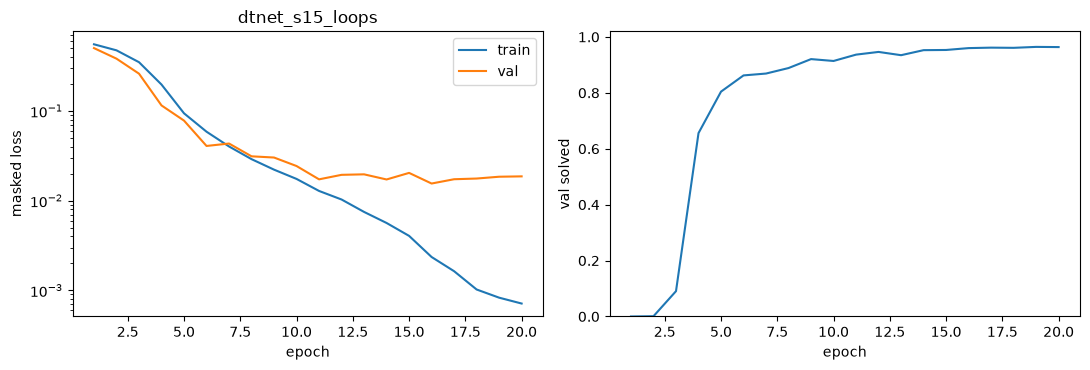

In [6]:
history = json.loads((RESULTS / RUN / "history.json").read_text())
plot_history(history, cfg)
plt.show()

## Data

Training mazes are split evenly across the training generators. With `train_wr > 0`, walls
are removed from training mazes too (a range draws one fraction per maze). Test mazes come
from generators the model never saw; `extrap/<size>` sets (if any) are larger mazes from the
training generators. Mazes are generated on demand, so this only builds the ones shown.

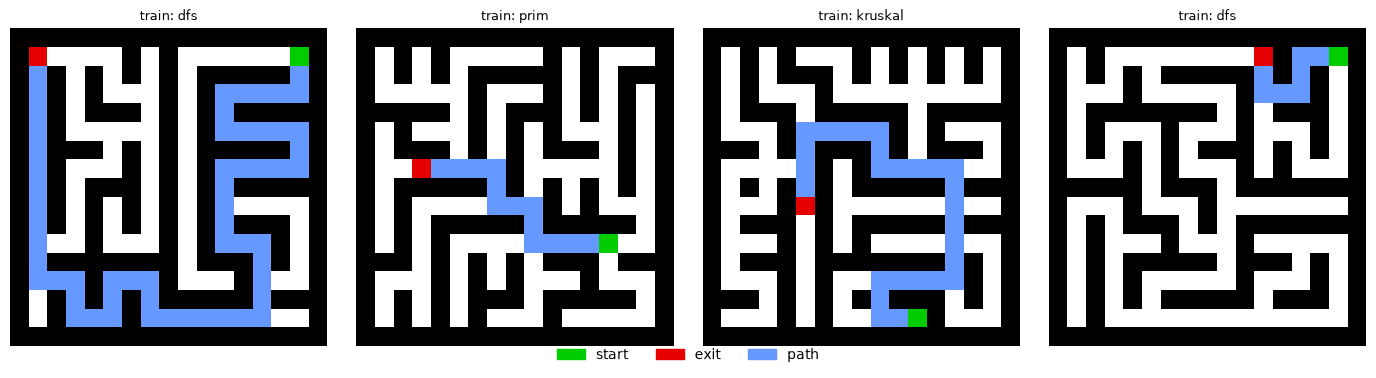

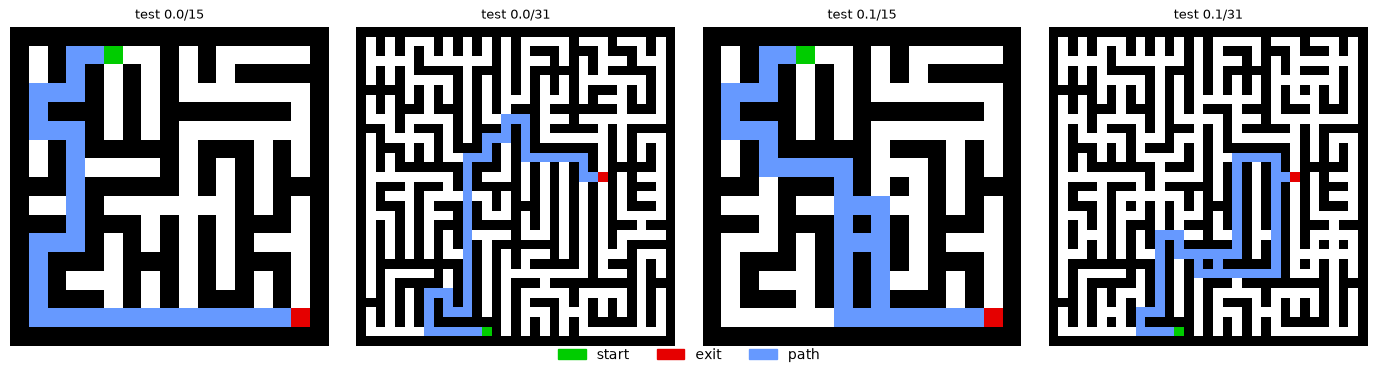

In [7]:
# One colour per meaning, shared by every maze image (RGB).
COLORS = {
    "start": (0.0, 0.8, 0.0),           # green
    "exit": (0.9, 0.0, 0.0),            # red
    "path": (0.4, 0.6, 1.0),            # blue: (correctly predicted) shortest-path pixel
    "missed": (1.0, 0.6, 0.1),          # orange: path pixel not predicted (on a tied route)
    "missed (gap)": (0.6, 0.3, 0.0),    # brown: missed pixel every shortest path uses
    "extra": (0.9, 0.2, 0.9),           # magenta: predicted, not on a shortest path
    "extra (dead end)": (0.5, 0.2, 0.7),  # purple: extra pixel in a dead end
}


def _base(x):
    """Black wall, white passage, as an H x W x 3 float array."""
    return np.repeat(np.asarray(x[0], dtype=float)[..., None], 3, -1)


def _endpoints(img, x):
    img[np.asarray(x[1]) > 0.5] = COLORS["start"]
    img[np.asarray(x[2]) > 0.5] = COLORS["exit"]
    return img


def render(x, y=None, pred=None):
    """Maze image; with `y` the path in blue, with `pred` too the missed and extra pixels."""
    img = _base(x)
    if y is not None:
        target = np.asarray(y[0]) > 0.5
        predicted = target if pred is None else np.asarray(pred[0]) > 0.5
        img[target & predicted] = COLORS["path"]
        img[target & ~predicted] = COLORS["missed"]
        img[~target & predicted] = COLORS["extra"]
    return _endpoints(img, x)


def show(images, titles=(), ncols=4, legend=(), title=None, save=None):
    """Images in a grid, with a legend for the given COLORS keys; optionally saved to `save`."""
    ncols = min(ncols, len(images))
    nrows = -(-len(images) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 3.5 * nrows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(images):
            ax.imshow(images[i])
            ax.set_title(titles[i] if i < len(titles) else "", fontsize=9)
    if legend:
        fig.legend([Patch(color=COLORS[k], label=k) for k in legend], legend, loc="lower center",
                   ncol=len(legend), frameon=False, bbox_to_anchor=(0.5, -0.04))
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    if save:
        fig.savefig(save, dpi=110, bbox_inches="tight")
    plt.show()


train_set = make_train_dataset(list(cfg.train_generators), size=cfg.train_size, num_samples=cfg.n_train,
                               seed=cfg.seed, wall_removal=cfg.train_wr)
# Result key ("<wall removal>/<size>" or "extrap/<size>") -> lazily generated dataset
test_sets = {key: make_dataset() for key, (make_dataset, _, _) in eval_sets(cfg).items()}

n_gen = len(train_set.generator_names)
show([render(*train_set[i]) for i in range(4)],
     titles=[f"train: {train_set.generator_names[i % n_gen]}" for i in range(4)],
     legend=("start", "exit", "path"))
examples = [f"{wr}/{size}" for wr in cfg.test_wr for size in list(cfg.test_sizes)[:2]]
show([render(*test_sets[key][0]) for key in examples], titles=[f"test {key}" for key in examples],
     legend=("start", "exit", "path"))

## Test on unseen generators

Fraction of test mazes solved, per test set (`<wall removal>/<size>`) and iteration count.
Results come from `results/<RUN>/results.json`; sets missing there (or all of them, with
`REEVALUATE = True`) are evaluated from the checkpoint, which is slow for large mazes and
isn't written back. The feedforward baseline has a fixed depth, so it has a single "iteration"
count and larger mazes cannot get more computation.

In [11]:
saved_path = RESULTS / RUN / "results.json"
saved = {} if REEVALUATE or not saved_path.exists() else normalize_results(json.loads(saved_path.read_text()))
if eval_sets(cfg).keys() <= saved.keys():
    results = saved
else:
    t0 = time.time()
    results = run(cfg, checkpoint=checkpoint, skip_train=True, results=saved, progress=True)["results"]
    print(f"evaluated in {time.time() - t0:.0f}s\n")

iters = list(cfg.test_iters)
print(f"{'test set':>12} " + " ".join(f"{t:>7}" for t in iters) + "   (iterations)")
for key in eval_sets(cfg):
    print(f"{key:>12} " + " ".join(f"{results[key][t]:>7.1%}" for t in iters))

    test set      30     100     300    1000    3000   (iterations)
      0.0/15  100.0%   95.6%   95.6%   95.6%   95.6%
      0.0/31   59.2%   66.8%   68.4%   69.2%   70.8%
      0.0/63   13.5%   16.5%   16.5%   16.0%   16.0%
     0.0/127    3.0%    5.0%    4.0%    4.0%    5.0%
     0.0/255    2.5%    2.5%    2.5%    2.5%    2.5%
     0.0/511    0.0%    0.0%    0.0%    0.0%    0.0%
      0.1/15   94.4%   87.2%   86.0%   86.4%   86.0%
      0.1/31   53.6%   54.0%   52.4%   53.6%   53.2%
      0.1/63   11.5%   14.5%   14.5%   14.0%   14.0%
     0.1/127    4.0%    3.0%    4.0%    5.0%    5.0%


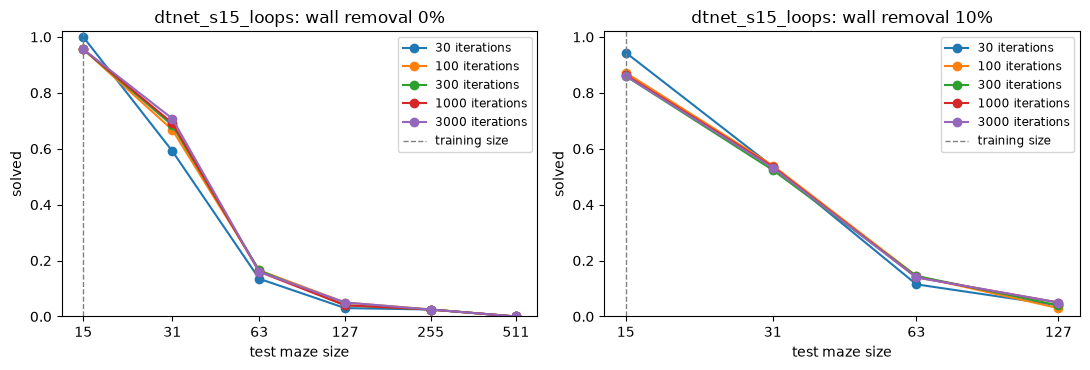

In [12]:
fig, axes = plt.subplots(1, len(cfg.test_wr), figsize=(5.5 * len(cfg.test_wr), 3.8), squeeze=False)

for ax, wr in zip(axes[0], cfg.test_wr):
    sizes = [s for s in cfg.test_sizes if f"{wr}/{s}" in results]
    for t in iters:
        label = f"{t} iterations" if cfg.model != "ff" else "one forward pass"
        ax.plot(sizes, [results[f"{wr}/{s}"][t] for s in sizes], marker="o", label=label)
    ax.axvline(cfg.train_size, color="gray", ls="--", lw=1, label="training size")
    ax.set(xscale="log", xlabel="test maze size", ylabel="solved", ylim=(0, 1.02),
           title=f"{RUN}: wall removal {wr:.0%}")
    ax.set_xticks(sizes, labels=sizes)
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.legend(fontsize="small")

plt.tight_layout()
plt.show()

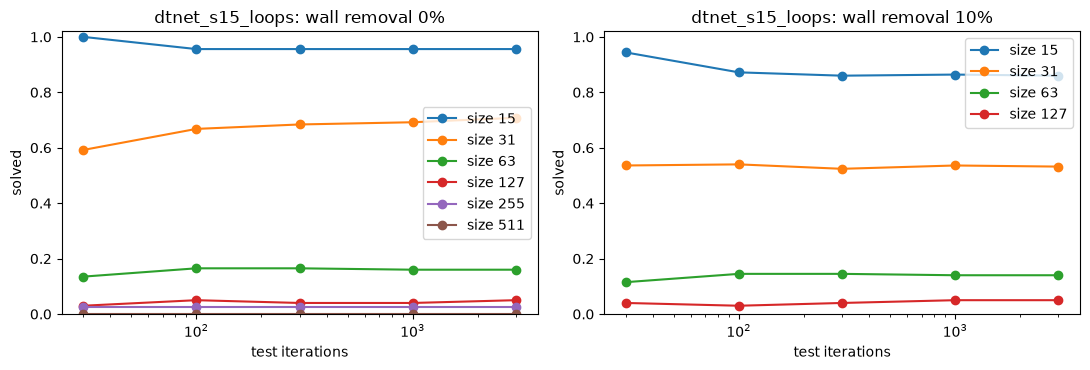

In [13]:
# Solved vs test iterations, one line per size (as in experiments.ipynb). DTNet only: the
# feedforward baseline has a single forward pass, so the plot above already says it all.
if cfg.model != "ff":
    plot_results(results, cfg)
    plt.show()

## Predictions

The first maze of every test set after the largest iteration count (size-511 mazes take about
a minute each at 3000 iterations). Blue = correctly predicted path, orange = missed path
pixels, magenta = extra (predicted but not on a shortest path).

predictions:   0%|          | 0/10 [00:00<?, ?it/s]

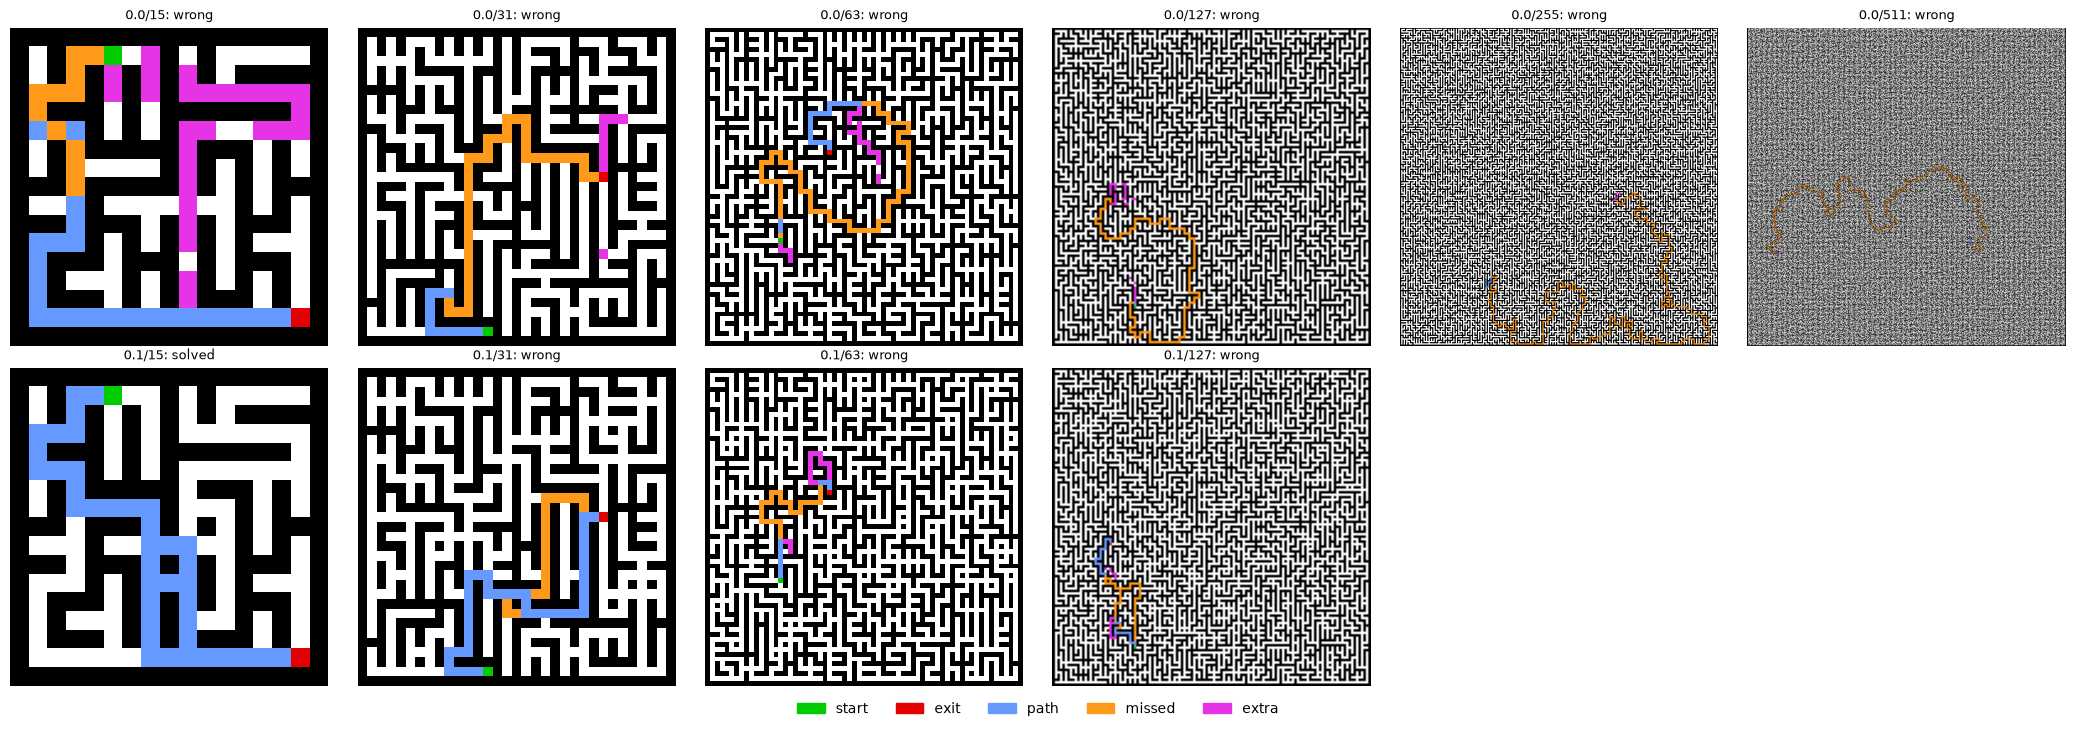

In [14]:
images, titles = [], []

for key, ds in tqdm(test_sets.items(), desc="predictions"):
    x, y = ds[0]
    with autocast:
        pred = M.predict(model, x[None].float().to(device), max(iters))[0].cpu()
    ok = bool(((pred == y) | (x[:1] == 0)).all())
    images.append(render(x, y, pred))
    titles.append(f"{key}: {'solved' if ok else 'wrong'}")

show(images, titles, ncols=len(cfg.test_sizes), legend=("start", "exit", "path", "missed", "extra"))

## Error analysis

Why does the model fail on a maze? For every failed test maze, each wrong passage pixel is put
in one of four categories:

| category | meaning | colour |
|---|---|---|
| `missed_forced` | a pixel that **every** shortest path uses is not marked: the path has a gap | brown |
| `missed_tied` | a pixel of one of several equally short routes is not marked | orange |
| `extra_route` | a marked pixel on a start–exit route that is not shortest (around a loop) | magenta |
| `extra_deadend` | a marked pixel in a dead end (removed by dead-end filling) | purple |

Also reported per setting: how many failed predictions still connect start and exit, and how
many are exactly one shortest path (`dataset.is_shortest_path`; such answers are correct but
count as failed, because the target marks all tied routes).

Test mazes are the first mazes of the run's own test sets (same generators and seed). Takes a
few minutes; writes `results/<RUN>/error_analysis.json` and `error_analysis.png`.

In [17]:
ERROR_ITERS = 300                          # test-time iterations (ignored by the feedforward baseline)
ERROR_SIZES = {15: 200, 31: 200, 63: 100}  # size -> number of test mazes
EXAMPLE_WR, EXAMPLE_SIZE, N_EXAMPLES = 0.1, 31, 3  # failed mazes to plot
ERROR_BATCH = 50
CATEGORIES = ("missed_forced", "missed_tied", "extra_route", "extra_deadend")

In [18]:
def route_region(open_, start, goal):
    """Pixels on some start-exit route: what is left after repeatedly filling dead ends."""
    keep = open_.copy()
    while True:
        p = np.pad(keep, 1)
        neighbours = p[:-2, 1:-1].astype(int) + p[2:, 1:-1] + p[1:-1, :-2] + p[1:-1, 2:]
        dead = keep & (neighbours <= 1)
        dead[start] = dead[goal] = False
        if not dead.any():
            return keep
        keep &= ~dead


def analyse(x, pred):
    """Error pixels per category, plus masks for plotting, for one maze (numpy x, bool pred)."""
    open_ = x[0] > 0.5
    start, goal = (tuple(np.argwhere(x[c] > 0.5)[0]) for c in (1, 2))
    from_start, from_goal = bfs_distances(open_, start), bfs_distances(open_, goal)
    length = from_start[goal]
    target = (from_start >= 0) & (from_goal >= 0) & (from_start + from_goal == length)
    # Forced = the only target pixel at its distance from the start.
    per_level = np.bincount(from_start[target], minlength=from_start.max() + 1)
    forced = target & (per_level[np.maximum(from_start, 0)] == 1)
    routes = route_region(open_, start, goal)
    extra = pred & ~target
    counts = {
        "missed_forced": int((forced & ~pred).sum()),
        "missed_tied": int((target & ~forced & ~pred).sum()),
        "extra_route": int((extra & routes).sum()),
        "extra_deadend": int((extra & ~routes).sum()),
    }
    info = {
        "connected": bool(bfs_distances(pred & open_, start)[goal] >= 0),
        "one_shortest_path": is_shortest_path(x[0].astype(np.uint8), start, goal, pred),
    }
    return counts, info, (target, forced, routes)


def render_errors(x, pred, masks):
    """Like render(), with missed and extra pixels split into the four error categories."""
    target, forced, routes = masks
    img = _base(x)
    img[pred & target] = COLORS["path"]
    img[forced & ~pred] = COLORS["missed (gap)"]
    img[target & ~forced & ~pred] = COLORS["missed"]
    img[pred & ~target & routes] = COLORS["extra"]
    img[pred & ~target & ~routes] = COLORS["extra (dead end)"]
    return _endpoints(img, x)

In [19]:
rows, summary, examples = [], {}, []

for wr in cfg.test_wr:
    for size, n in tqdm(ERROR_SIZES.items(), desc=f"wall removal {wr}"):
        ds = make_test_datasets(list(cfg.test_generators), size, n, list(cfg.train_generators),
                                seed=cfg.seed + 1, wall_removal=wr)[size]
        X = torch.stack([ds[i][0] for i in range(n)])
        preds = []
        with autocast:
            for b in range(0, n, ERROR_BATCH):
                preds.append(M.predict(model, X[b:b + ERROR_BATCH].to(device), ERROR_ITERS).cpu())
        P, Xn = torch.cat(preds)[:, 0].numpy() > 0.5, X.numpy()

        row = {"wall removal": wr, "size": size, "n": n, "failed": 0, "connected": 0,
               "one_shortest_path": 0, **{f"mazes {c}": 0 for c in CATEGORIES}, **{c: 0 for c in CATEGORIES}}
        for i in range(n):
            counts, info, masks = analyse(Xn[i], P[i])
            if not any(counts.values()):
                continue
            row["failed"] += 1
            row["connected"] += info["connected"]
            row["one_shortest_path"] += info["one_shortest_path"]
            for c, v in counts.items():
                row[c] += v
                row[f"mazes {c}"] += v > 0
            if (wr, size) == (EXAMPLE_WR, EXAMPLE_SIZE) and len(examples) < N_EXAMPLES:
                examples.append((Xn[i], P[i], masks, counts))

        rows.append(row)
        summary[f"{wr}/{size}"] = {k: v for k, v in row.items() if k not in ("wall removal", "size")}

(RESULTS / RUN / "error_analysis.json").write_text(json.dumps(summary, indent=1, default=int))
errors = pd.DataFrame(rows).set_index(["wall removal", "size"])

wall removal 0.0:   0%|          | 0/3 [00:00<?, ?it/s]

wall removal 0.1:   0%|          | 0/3 [00:00<?, ?it/s]

Failed mazes, and how many of them still connect start and exit or are exactly one shortest path:

In [21]:
errors[["n", "failed", "connected", "one_shortest_path"]]

n  failed  connected  one_shortest_path
wall removal size                                           
0.0          15    200       9          2                  0
             31    200      61          2                  0
             63    100      83          0                  0
0.1          15    200      28         24                  9
             31    200      93         37                 11
             63    100      87         13                  4

Share of the wrong pixels in each category (rows with no failures are empty):

In [22]:
shares = errors[list(CATEGORIES)].div(errors[list(CATEGORIES)].sum(axis=1), axis=0)
shares.style.format("{:.0%}", na_rep="-").background_gradient(cmap="Reds", vmin=0, vmax=1, axis=None)

Number of failed mazes with at least one wrong pixel of each category:

In [23]:
errors[[f"mazes {c}" for c in CATEGORIES]]

mazes missed_forced  mazes missed_tied  mazes extra_route  mazes extra_deadend
wall removal size                                                                                
0.0          15                      7                  0                  0                    7
             31                     59                  0                  0                   54
             63                     83                  0                  0                   77
0.1          15                      5                 21                  9                    3
             31                     63                 62                 69                    5
             63                     76                 64                 78                    4

The first failed mazes at the example setting, coloured by error category:

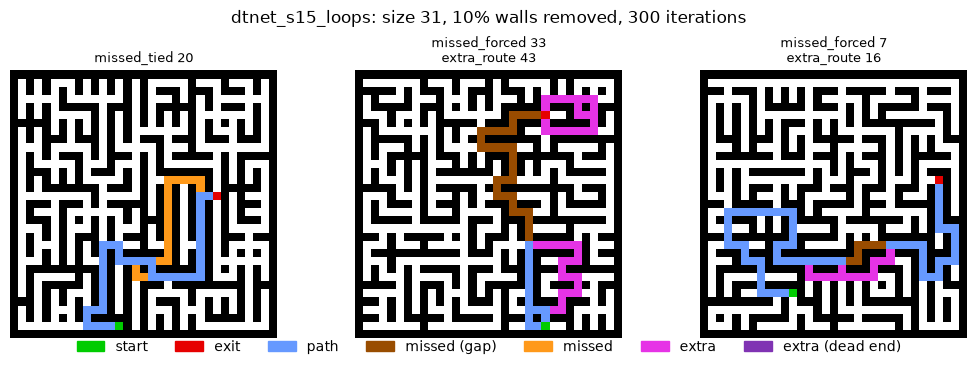

In [24]:
if not examples:
    print(f"{RUN}: no failures at wall removal {EXAMPLE_WR}, size {EXAMPLE_SIZE}")
else:
    show([render_errors(x, pred, masks) for x, pred, masks, _ in examples],
               titles=["\n".join(f"{c} {v}" for c, v in counts.items() if v) for *_, counts in examples],
               ncols=N_EXAMPLES,
               legend=("start", "exit", "path", "missed (gap)", "missed", "extra", "extra (dead end)"),
               title=f"{RUN}: size {EXAMPLE_SIZE}, {EXAMPLE_WR:.0%} walls removed, {ERROR_ITERS} iterations",
               save=RESULTS / RUN / "error_analysis.png")